# 05 · Full DDPM ELBO, ODE likelihood and distribution evaluation

Work through each likelihood term, inspect the learned variance head, and test metrics on deliberately flawed generators.

**Prerequisites:** 01–03; Gaussian KL, log densities and change of variables.

**By the end:** Decompose the complete ELBO; distinguish a bound from NLL; check divergence signs and probe variance; diagnose mode collapse beyond FID/IS.

Run from top to bottom. Default experiments use CPU, fixed seeds and no downloads. Small trained models illustrate learning; analytic oracles isolate mathematical and solver effects. Neither is an image-quality benchmark.

[Course index](README.md) · [Notation](../docs/23_notation_and_code.md) · [Implementation scope](../docs/15_coverage_and_scope.md)

In [1]:
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Image, display

project = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "diffusion_lab").is_dir())
if str(project) not in sys.path:
    sys.path.insert(0, str(project))
torch.set_num_threads(2)
torch.manual_seed(7)
np.random.seed(7)
plt.rcParams.update(
    {
        "figure.figsize": (10, 3.6),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.dpi": 100,
    }
)
ENABLE_WIDGETS = False  # Set True in Jupyter; static figures work on GitHub.
print(f"PyTorch {torch.__version__}; CPU lesson; seed=7; no automatic downloads.")


def scatter(ax, samples, title, labels=None, limits=(-4.5, 4.5)):
    points = samples.detach().cpu().numpy()
    colors = labels.detach().cpu().numpy() if labels is not None else "steelblue"
    ax.scatter(
        points[:, 0],
        points[:, 1],
        c=colors,
        cmap="tab10" if labels is not None else None,
        s=5,
        alpha=0.55,
        linewidths=0,
    )
    ax.set(title=title, xlabel="$x_1$", ylabel="$x_2$", aspect="equal", xlim=limits, ylim=limits)


def saved_gallery(relative, caption):
    path = project / relative
    if not path.is_file():
        raise FileNotFoundError(f"Missing curated course evidence: {relative}")
    print(caption)
    display(Image(filename=str(path)))


def animate_particles(history, name, title, labels=None, limits=(-4.5, 4.5)):
    from matplotlib.animation import FuncAnimation, PillowWriter

    points = history.detach().cpu().numpy()
    indices = np.linspace(0, len(points) - 1, min(32, len(points))).astype(int)
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    colors = labels.detach().cpu().numpy() if labels is not None else "steelblue"
    dots = ax.scatter(
        *points[0].T,
        c=colors,
        cmap="tab10" if labels is not None else None,
        s=9,
        alpha=0.65,
        linewidths=0,
    )
    ax.set(xlim=limits, ylim=limits, aspect="equal", xlabel="$x_1$", ylabel="$x_2$")

    def update(frame):
        dots.set_offsets(points[indices[frame]])
        ax.set_title(f"{title}: frame {frame + 1}/{len(indices)}")
        return (dots,)

    animation = FuncAnimation(fig, update, frames=len(indices), interval=100)
    folder = project / "assets/teaching/notebooks"
    folder.mkdir(parents=True, exist_ok=True)
    target = folder / f"{name}.gif"
    animation.save(target, writer=PillowWriter(fps=10), dpi=75)
    plt.close(fig)
    display(Image(filename=str(target)))

PyTorch 2.7.1+cu128; CPU lesson; seed=7; no automatic downloads.


## 1. The full DDPM negative ELBO

$$\mathcal L_{\rm VLB}=\underbrace{D_{KL}(q(x_T|x_0)\|p(x_T))}_{L_T}
+\underbrace{\sum_{k=2}^T\mathbb E_qD_{KL}(q(x_{k-1}|x_k,x_0)\|p_\theta(x_{k-1}|x_k))}_{\text{transition sum}}
-\underbrace{\mathbb E_q\log p_\theta(x_0|x_1)}_{\text{decoder log likelihood}}.$$
Divide nats by $D\log2$ for bits/dimension. It bounds NLL from above in expectation;
a noisy single Monte Carlo estimate is not an exact likelihood or a pointwise guaranteed bound.
The continuous toy decoder uses a Gaussian density; 8-bit images use discretized
Gaussian bin probabilities, with special treatment at pixel boundaries.
The first decoder term and terminal prior must not be omitted.

**Equation → code:** `ddpm_elbo`, `prior_kl_bpd` in [likelihood.py](../diffusion_lab/likelihood.py);
`variational_bound` and tail-stable decoder in [improved_ddpm.py](../diffusion_lab/improved_ddpm.py).

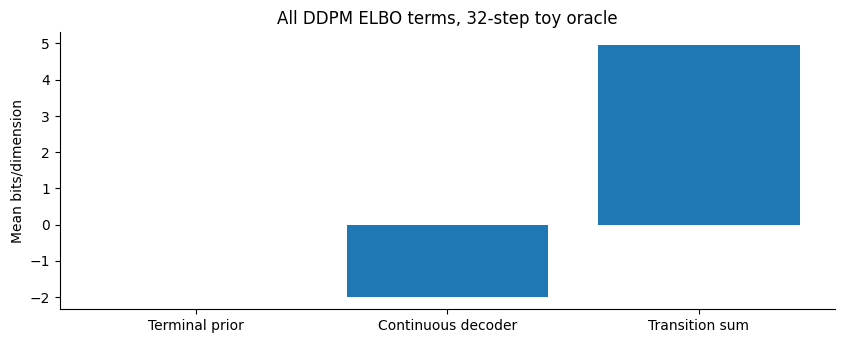

Mean total: 2.9724595045988322 calls: 32
Exact NLL? False — All T terms; one Monte Carlo noise draw per term


In [2]:
from diffusion_lab.data import GaussianMixture
from diffusion_lab.likelihood import ddpm_elbo
from diffusion_lab.paths import DiscreteVP, expand

mixture = GaussianMixture()
path = DiscreteVP(32, "cosine")


class OracleNoise(torch.nn.Module):
    def forward(self, x, t, labels=None):
        a, s = path.coefficients(t)
        return -expand(s, x) * mixture.score(x, a, s, labels)


clean, _ = mixture.sample(64, torch.Generator().manual_seed(61))
full = ddpm_elbo(
    OracleNoise(),
    path,
    clean,
    quantized=False,
    clip_x0=False,
    generator=torch.Generator().manual_seed(62),
)
parts = ["terminal_prior_kl_bpd", "decoder_bpd", "transition_kl_bpd"]
torch.testing.assert_close(full["negative_elbo_bpd"], sum(full[key] for key in parts))
fig, ax = plt.subplots()
ax.bar(
    ["Terminal prior", "Continuous decoder", "Transition sum"],
    [full[key].mean().item() for key in parts],
)
ax.set(ylabel="Mean bits/dimension", title="All DDPM ELBO terms, 32-step toy oracle")
plt.show()
print("Mean total:", full["negative_elbo_bpd"].mean().item(), "calls:", full["network_calls"])
print("Exact NLL?", full["is_exact_nll"], "—", full["estimator"])

## 2. Learn diagonal variance and reweight objectives

Improved DDPM predicts a per-coordinate variance head, not a dense covariance.
Its learned-range convention is
$$\log\Sigma_\theta=v\log\beta_k+(1-v)\log\widetilde\beta_k,\quad
v=(h_\theta+1)/2.$$
The published parameterization does **not** clamp $h_\theta$.
Hybrid training combines simple MSE with a small weighted VLB term, detaching
the mean prediction inside that VLB term so variance supervision does not
change its mean branch gradient. A pure VLB objective uses a different gradient path.
Loss-second-moment timestep sampling changes sampling probabilities and uses
importance weights; it is not just changing the beta schedule.
**Code:** `learned_log_variance`, `improved_loss`, `LossSecondMomentSampler` in [improved_ddpm.py](../diffusion_lab/improved_ddpm.py).

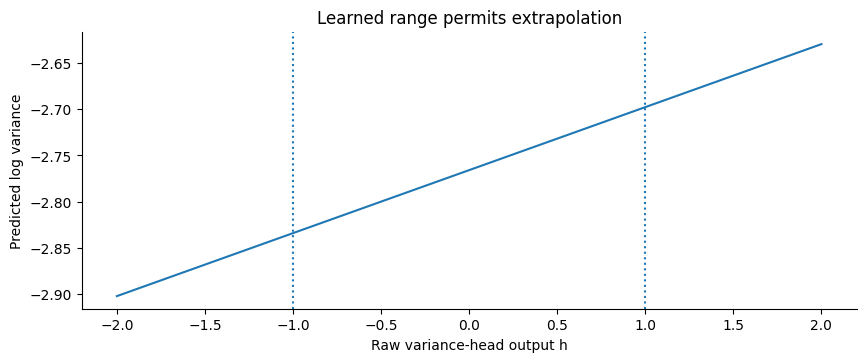

Detached mean: no VLB mean gradient; variance gradient norm: 0.002350935246795416


In [3]:
from diffusion_lab.improved_ddpm import learned_log_variance, posterior, variational_bound

index = torch.full((len(clean),), 12, dtype=torch.long)
t = (index.float() + 1) / path.steps
a, s = path.coefficients(t)
eps = torch.randn_like(clean)
noisy = expand(a, clean) * clean + expand(s, clean) * eps
_, minimum = posterior(path, clean, noisy, index)
maximum = path.betas[index].log()
fig, ax = plt.subplots()
values = torch.linspace(-2, 2, 100)[:, None].repeat(1, 2)
interpolated = learned_log_variance(values, minimum[:1].repeat(100), maximum[:1].repeat(100))
ax.plot(values[:, 0], interpolated[:, 0])
ax.axvline(-1, ls=":")
ax.axvline(1, ls=":")
ax.set(
    xlabel="Raw variance-head output h",
    ylabel="Predicted log variance",
    title="Learned range permits extrapolation",
)
plt.show()
estimate = torch.randn_like(clean, requires_grad=True)
variance_head = torch.zeros_like(clean, requires_grad=True)
vb = variational_bound(path, clean, noisy, index, estimate, variance_head, detach_mean=True).mean()
vb.backward()
assert estimate.grad is None
assert variance_head.grad is not None and torch.isfinite(variance_head.grad).all()
print(
    "Detached mean: no VLB mean gradient; variance gradient norm:", variance_head.grad.norm().item()
)

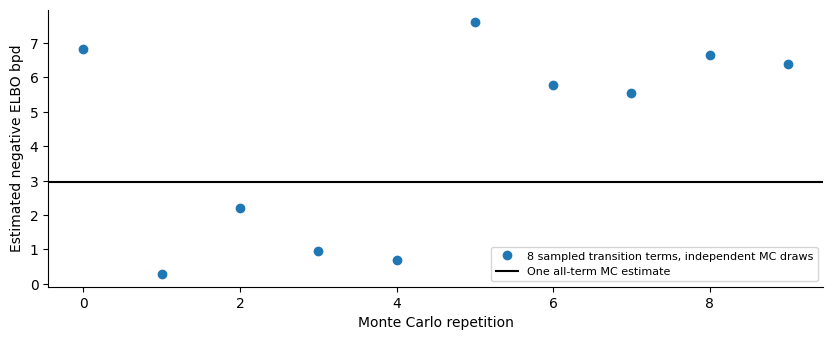

Each sampled run uses 9 calls: one decoder plus eight transitions.


In [4]:
sampled_means = []
for seed in range(10):
    estimate = ddpm_elbo(
        OracleNoise(),
        path,
        clean,
        quantized=False,
        clip_x0=False,
        timestep_samples=8,
        generator=torch.Generator().manual_seed(70 + seed),
    )
    sampled_means.append(estimate["negative_elbo_bpd"].mean().item())
plt.plot(sampled_means, "o", label="8 sampled transition terms, independent MC draws")
plt.axhline(
    full["negative_elbo_bpd"].mean().item(), color="black", label="One all-term MC estimate"
)
plt.xlabel("Monte Carlo repetition")
plt.ylabel("Estimated negative ELBO bpd")
plt.legend(fontsize=8)
plt.show()
print(
    "Each sampled run uses", estimate["network_calls"], "calls: one decoder plus eight transitions."
)

## 3. ODE likelihood: get the sign right

Along $\dot x=u$, $d\log p_t(x_t)/dt=-\nabla\cdot u$.
Integrating a datum toward a known base gives
$$\log p_{\rm data}(x)=\log p_{\rm base}(x_T)+\int\nabla\cdot u(x_t,t)dt.$$
For $u=ax$ over unit time and a unit Gaussian terminal law, the initial
standard deviation is $e^{-a}$. This analytic case isolates numerical error.
**Code:** `ode_log_density`, `field_and_divergence` in [likelihood.py](../diffusion_lab/likelihood.py).

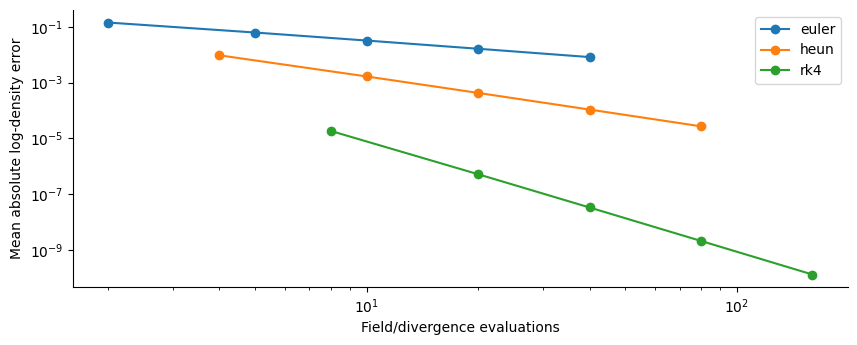

In [5]:
from diffusion_lab.likelihood import field_and_divergence, gaussian_log_density, ode_log_density

x = torch.randn(64, 2, generator=torch.Generator().manual_seed(81), dtype=torch.float64)
exact = gaussian_log_density(x, std=math.exp(-0.4))
fig, ax = plt.subplots()
for method in ["euler", "heun", "rk4"]:
    costs, errors = [], []
    for steps in [2, 5, 10, 20, 40]:
        estimated, metadata = ode_log_density(
            lambda x, t: 0.4 * x,
            x,
            torch.linspace(0, 1, steps + 1, dtype=x.dtype),
            gaussian_log_density,
            solver=method,
            trace="exact",
        )
        costs.append(metadata["field_calls"])
        errors.append((estimated - exact).abs().mean().item())
    ax.loglog(costs, errors, "o-", label=method)
ax.set(xlabel="Field/divergence evaluations", ylabel="Mean absolute log-density error")
ax.legend()
plt.show()
assert errors[-1] < 1e-8

## 4. Stochastic traces have their own uncertainty

Hutchinson uses $\mathbb E_z[z^TJz]=\operatorname{tr}J$, with zero-mean,
unit-covariance probes. The implementation uses Rademacher probes, held fixed
through each ODE solve. Resampling at every RHS evaluation would create a noisy
ODE right-hand side. Probe repetitions differ from sampling seeds or training seeds.

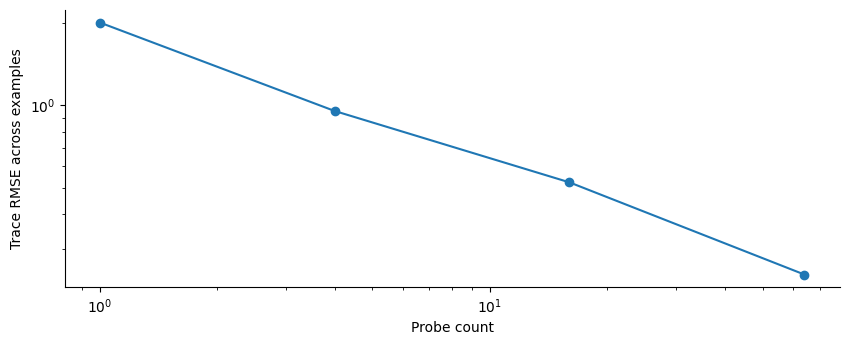

Exact divergence: 0.30000000000000004


In [6]:
matrix = torch.tensor([[0.4, 1.2], [0.8, -0.1]], dtype=torch.float64)


def field(x, t):
    return x @ matrix.T


t = torch.zeros(len(x), dtype=x.dtype)
_, exact_trace = field_and_divergence(field, x, t)
counts = [1, 4, 16, 64]
deviations = []
for count in counts:
    g = torch.Generator().manual_seed(82)
    probes = (2 * torch.randint(2, (count, *x.shape), generator=g) - 1).to(x)
    _, estimated_trace = field_and_divergence(field, x, t, probes)
    deviations.append((estimated_trace - exact_trace).square().mean().sqrt().item())
plt.loglog(counts, deviations, "o-")
plt.xlabel("Probe count")
plt.ylabel("Trace RMSE across examples")
plt.show()
print("Exact divergence:", matrix.trace().item())

## 5. Metrics respond differently to collapse and outliers

MMD compares kernel means; sliced $W_2$ compares projected quantiles.
Precision asks whether generated features lie in the reference manifold;
recall asks how much reference support is represented. Density/coverage add
neighborhood information. Results depend on feature space, counts and $k$.
Below the **features are 2D coordinates**, not Inception embeddings; these are not image FID scores.
Unbiased MMD² can be negative. IS uses generated class predictions and does not
compare against real images. FID matches Gaussian feature moments and can miss
differences beyond them. No single score proves good images or non-memorization.
**Code:** [metrics.py](../diffusion_lab/metrics.py), [distribution_metrics.py](../diffusion_lab/distribution_metrics.py).

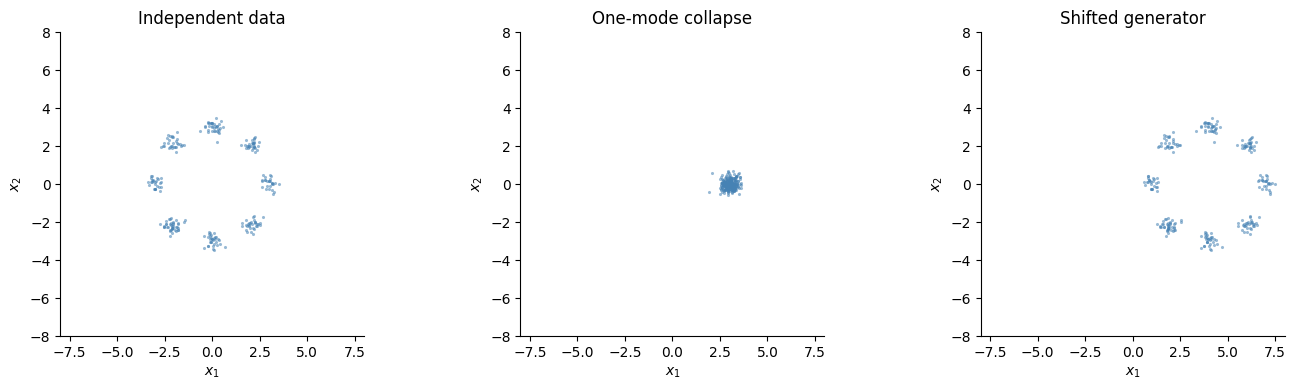

{'precision': 0.9531, 'recall': 0.9141, 'density': 1.0417, 'coverage': 0.8672, 'name': 'Independent data', 'mmd2': -0.0031, 'sliced_w2': 0.2251}
{'precision': 0.8789, 'recall': 0.1289, 'density': 1.0078, 'coverage': 0.1289, 'name': 'One-mode collapse', 'mmd2': 0.5642, 'sliced_w2': 2.8607}
{'precision': 0.2461, 'recall': 0.2539, 'density': 0.276, 'coverage': 0.25, 'name': 'Shifted generator', 'mmd2': 0.144, 'sliced_w2': 2.8335}


In [7]:
from diffusion_lab.distribution_metrics import manifold_metrics
from diffusion_lab.metrics import mmd_squared, sliced_wasserstein

g = torch.Generator().manual_seed(83)
real, _ = mixture.sample(256, g)
good, _ = mixture.sample(256, g)
collapsed, _ = mixture.sample(256, g, labels=torch.zeros(256, dtype=torch.long))
outliers = good + torch.tensor([4.0, 0.0])
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
rows = []
for ax, (name, samples) in zip(
    axes,
    [("Independent data", good), ("One-mode collapse", collapsed), ("Shifted generator", outliers)],
    strict=True,
):
    scatter(ax, samples, name, limits=(-8, 8))
    row = manifold_metrics(real, samples, k=3)
    row.update(
        name=name, mmd2=mmd_squared(real, samples), sliced_w2=sliced_wasserstein(real, samples, 64)
    )
    rows.append(row)
plt.tight_layout()
plt.show()
for row in rows:
    print(
        {
            key: round(value, 4) if isinstance(value, float) else value
            for key, value in row.items()
            if key in ["name", "precision", "recall", "density", "coverage", "mmd2", "sliced_w2"]
        }
    )

## Exercises and worked answers

1. Which DDPM term is missing if you average only noise MSE over time?
2. Does increasing ODE steps remove Hutchinson error? Does increasing probes remove discretization error?
3. Can a collapsed model have high precision but low recall?

<details><summary>Worked answers</summary>

1. Noise MSE is a surrogate with different time weights; it is not the decoder + transition KL sum + terminal prior decomposition.
2. Neither eliminates the other source of error. Evaluate grid, probe and endpoint sensitivity separately.
3. Yes: plausible samples from one mode may lie in the reference manifold while failing to cover other modes.

</details>

**Actual reports:** [Likelihood](../docs/16_likelihood_and_elbo.md), [evaluation](../docs/19_evaluation_beyond_fid.md),
[seed studies](../docs/25_evidence_studies.md), [latest measured failures](../docs/28_scratch_and_refinement.md).
**Continue:** [Text conditioning](06_text_cross_attention.ipynb).
**Sources:** [Improved DDPM](https://arxiv.org/abs/2102.09672), [density/coverage](https://proceedings.mlr.press/v119/naeem20a.html).